# Etapa B · Hipótesis 1: el sesgo del viento es sistemático

En la Etapa A (`distribucion-errores.ipynb`) se vio que el pronóstico de velocidad del viento **sobreestima** la observación
en ≈ +2,9 km/h en promedio. Este notebook contrasta formalmente si ese sesgo es **sistemático** o si podría deberse
simplemente al azar de la muestra.

Se parte del dataset limpio que exporta `relaciones-bivariadas.ipynb` (secc. 1) y de la lista de estaciones sospechosas de
falla del sensor que exporta `distribucion-errores.ipynb` (secc. 3). El error se define como **pronosticado − observado**,
igual que en la Etapa A: un error positivo indica que el pronóstico **sobreestima** el viento.

**Cómo leer este notebook.** Antes de usar cada estadístico hay una celda titulada *«Qué es…»* que explica en términos
sencillos qué mide y cómo se interpreta. El recorrido es:

1. Carga de los datos.
2. Planteo de la hipótesis.
3. El sesgo en la muestra.
4. Un primer test «ingenuo» sobre todos los pares, y por qué no es válido.
5. Cambio de unidad de análisis: un valor por estación.
6. a 9. Cuatro contrastes sobre las estaciones: test t, Wilcoxon, test de signos y bootstrap.
10. Tamaño del efecto.
11. Chequeo de robustez: por red.
12. Resumen de los contrastes.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo, cargar_mediciones_limpias

In [2]:
PROCESSED = '../data/processed/'  # incluye tabla_estaciones_sospechosas.csv, que calcula distribucion-errores.ipynb
OUT = '../data/processed/hipotesis/'

COL = 'error_windspeed_kmh'
ALFA = 0.05            # nivel de significación
N_MIN_ESTACION = 100   # pares mínimos de una estación, como en distribucion-errores.ipynb (secc. 4)
N_MIN_RED = 10         # estaciones mínimas de una red para analizarla por separado
N_BOOT = 10_000        # remuestras del bootstrap
SEMILLA = 42

# Paleta y estilo de los gráficos: notebooks/utils.py
aplicar_estilo()

figuras = {}     # se exportan todas al final
resultados = {}  # una fila por contraste, para la tabla resumen


def formato_p(p):
    """p-valor legible: decimal si es grande, notación científica si es muy chico."""
    if p == 0:
        return '< 1e-300'
    return f'{p:.3f}' if p >= 0.001 else f'{p:.1e}'


def decision(p):
    return 'Se rechaza H₀' if p < ALFA else 'No se rechaza H₀'

## 1. Carga de los datos

Se usan los pares pronóstico–observación de viento, sin las estaciones sospechosas de falla del anemómetro
(sensor trabado o defectuoso): en ellas el error refleja el sensor y no el pronóstico.

In [3]:
mp = cargar_mediciones_limpias()

sospechosas = pd.read_csv(PROCESSED + 'tabla_estaciones_sospechosas.csv')
sospechosas = sospechosas.loc[sospechosas['Variable'] == 'Velocidad del viento', 'station_id'].unique()

viento = mp[mp[COL].notna() & ~mp['station_id'].isin(sospechosas)].copy()
print(f'{len(viento):,} pares de viento en {viento["station_id"].nunique()} estaciones '
      f'({len(sospechosas)} estaciones sospechosas excluidas: {", ".join(sorted(sospechosas))})')
print(f'Período: {viento["fcst_target_timestamp"].min():%d/%m/%Y} a {viento["fcst_target_timestamp"].max():%d/%m/%Y}')

184,322 pares de viento en 329 estaciones (5 estaciones sospechosas excluidas: ALMW3, AP732, AR256, AR709, AS276)
Período: 01/09/2026 a 28/09/2026


## 2. Planteo de la hipótesis

### Qué es un test de hipótesis

Un test de hipótesis es una forma ordenada de responder: *«lo que veo en mis datos, ¿podría haber salido por pura
casualidad?»*. Funciona como un juicio, donde se presume la inocencia hasta que la evidencia diga lo contrario:

- **Hipótesis nula (H₀)**: la postura «aburrida», la que se da por cierta mientras no haya evidencia en contra.
  Acá: *el pronóstico no tiene sesgo*, y el +2,9 km/h salió por azar.
- **Hipótesis alternativa (H₁)**: lo que se quiere demostrar. Acá: *el pronóstico sí tiene sesgo*.
- **p-valor**: la probabilidad de obtener un resultado tan extremo como el observado (o más) **si H₀ fuera cierta**.
  Un p-valor chico significa que los datos serían muy raros en un mundo sin sesgo, así que se descarta ese mundo.
- **Nivel de significación (α)**: el umbral que se fija *antes* de mirar el resultado. Si p < α, se rechaza H₀.
  Se usa α = 0,05: se acepta equivocarse 1 de cada 20 veces al declarar un sesgo que en realidad no existe.

### Hipótesis de este notebook

Sea μ el sesgo medio verdadero del pronóstico de viento (pronosticado − observado, en km/h):

- **H₀: μ = 0** — el pronóstico no tiene sesgo.
- **H₁: μ ≠ 0** — el pronóstico tiene sesgo.

El contraste es **bilateral** (μ ≠ 0 y no μ > 0) porque la hipótesis surgió de mirar estos mismos datos en la Etapa A.
Elegir la dirección después de ver el resultado sería hacerse trampa: un test unilateral hace más fácil rechazar H₀.

## 3. El sesgo en la muestra

### Qué son la media, el desvío estándar y el error estándar

- **Media del error (sesgo)**: el promedio de todos los errores. Si los errores por exceso y por defecto se compensaran,
  daría 0. Una media positiva indica que, en promedio, el pronóstico se pasa.
- **Desvío estándar (s)**: cuánto se aleja, típicamente, **un error individual** de la media. Mide la dispersión de
  los datos.
- **Error estándar (EE = s / √n)**: cuánto cambiaría **la media** si se repitiera el estudio con otra muestra del mismo
  tamaño. Mide la precisión de la media, no la dispersión de los datos: cuantas más observaciones (n), más chico es.

La diferencia entre los dos últimos es la clave de todo el notebook: un error individual puede variar mucho (desvío
grande) y aun así la media estar estimada con mucha precisión (error estándar chico).

In [4]:
e = viento[COL]
media, desvio, n = e.mean(), e.std(), len(e)
ee = desvio / np.sqrt(n)
print(f'n = {n:,} pares')
print(f'Sesgo (media del error) = {media:+.2f} km/h')
print(f'Desvío estándar         = {desvio:.2f} km/h')
print(f'Error estándar          = {ee:.4f} km/h  (suponiendo pares independientes)')

n = 184,322 pares
Sesgo (media del error) = +2.89 km/h
Desvío estándar         = 5.74 km/h
Error estándar          = 0.0134 km/h  (suponiendo pares independientes)


## 4. Primer intento: test t sobre todos los pares

### Qué es el test t de una muestra

Responde a la pregunta: *«¿la media que observé está lo bastante lejos de 0 como para no atribuirla al azar?»*.
Para eso calcula un único número:

$$t = \frac{\text{media}}{\text{error estándar}} = \frac{\bar{x} - 0}{s / \sqrt{n}}$$

Es decir, **a cuántos errores estándar de distancia está la media del valor que propone H₀** (el 0).

- Si t está cerca de 0, la media es compatible con «no hay sesgo».
- Si |t| es mayor que ≈ 2, un resultado así ocurriría menos del 5 % de las veces si H₀ fuera cierta, y se rechaza H₀.

Tiene dos supuestos:

1. Que las observaciones sean **independientes** entre sí (que una no dé información sobre otra).
2. Que la media se comporte de forma aproximadamente normal, algo que con muchas observaciones se cumple aunque los
   datos individuales no sean normales (teorema central del límite).

In [5]:
t_pares = stats.ttest_1samp(e, 0)
print(f't = {t_pares.statistic:.1f}   p-valor = {formato_p(t_pares.pvalue)}   (n = {n:,})')

t = 216.4   p-valor = < 1e-300   (n = 184,322)


### Por qué este resultado no es válido

El resultado es t = 216,4: la media queda a más de 200 errores estándar del 0, y el p-valor es prácticamente 0
(< 10⁻³⁰⁰). Pero el test supone que los pares son **independientes**, y acá no lo son:

- **En el tiempo**: si el pronóstico de una estación se pasó a las 14 h, lo más probable es que también se pase a las 15 h.
- **En el espacio**: estaciones vecinas comparten el mismo error a la misma hora, porque las afecta el mismo fenómeno
  (casi la mitad de las estaciones son de CENTERPOINT, en el área de Houston).

Cuando los datos se repiten así, 184 mil pares **no aportan 184 mil datos de información**. El error estándar real es
bastante mayor que s/√n, y el test t «ingenuo» exagera la evidencia. Este problema se llama *pseudorreplicación*.

### Qué es la autocorrelación

La **autocorrelación de lag 1** mide cuánto se parece el error de una hora al de la hora anterior en la misma estación.
Es una correlación común y corriente, entre la serie y ella misma desplazada una hora:

- Cerca de **0**: cada hora es una sorpresa nueva; los errores son independientes.
- Cerca de **1**: el error de una hora es casi una copia del de la hora anterior.

Se calcula restando antes el sesgo propio de cada estación (para que no la infle) y usando solo los pares de horas
realmente consecutivas. El análisis completo de la persistencia del error está en `patrones-temporales.ipynb`.

In [6]:
v = viento.sort_values(['station_id', 'fcst_target_timestamp'])
v['centrado'] = v[COL] - v.groupby('station_id')[COL].transform('mean')
previo = v.groupby('station_id')[['centrado', 'fcst_target_timestamp']].shift()
consecutivas = (v['fcst_target_timestamp'] - previo['fcst_target_timestamp']) == pd.Timedelta(hours=1)
r1_pares = v.loc[consecutivas, 'centrado'].corr(previo.loc[consecutivas, 'centrado'])
print(f'Autocorrelación de lag 1 del error dentro de cada estación: r = {r1_pares:.2f} '
      f'({consecutivas.sum():,} pares de horas consecutivas)')

Autocorrelación de lag 1 del error dentro de cada estación: r = 0.64 (170,785 pares de horas consecutivas)


La autocorrelación de lag 1 es **r = 0,64** (sobre 170.785 pares de horas consecutivas): el error de una hora repite buena
parte del de la hora anterior. Los pares no son independientes, así que el t = 216,4 exagera la evidencia y queda
solo como referencia. Hay que cambiar la **unidad de análisis**.

## 5. Unidad de análisis: la estación

En lugar de tratar cada par como un dato, se resume **cada estación en un único número: su sesgo medio** de todo el
período. Así las miles de horas correlacionadas de una estación cuentan como una sola observación, y la pregunta pasa a
ser: *«el sesgo de una estación típica, ¿es distinto de 0?»*.

Se usan las estaciones con al menos 100 pares, el mismo mínimo que en la Etapa A, para que el sesgo de cada una
esté bien estimado.

In [7]:
por_estacion = viento.groupby('station_id').agg(Pares=(COL, 'size'), Sesgo=(COL, 'mean'), red=('red', 'first'))
por_estacion = por_estacion[por_estacion['Pares'] >= N_MIN_ESTACION]
x = por_estacion['Sesgo']
n_est = len(x)

pd.Series({
    'Estaciones': n_est,
    'Sesgo medio (km/h)': x.mean(),
    'Sesgo mediano (km/h)': x.median(),
    'Desvío estándar entre estaciones (km/h)': x.std(),
    'Estaciones que sobreestiman': (x > 0).sum(),
    '% que sobreestiman': (x > 0).mean() * 100,
    'Asimetría': stats.skew(x),
}).round(2).to_frame('Sesgo por estación')

,Sesgo por estación
Estaciones,325.00
Sesgo medio (km/h),3.34
Sesgo mediano (km/h),2.80
Desvío estándar entre estaciones (km/h),3.43
Estaciones que sobreestiman,275.00
% que sobreestiman,84.62
Asimetría,0.84


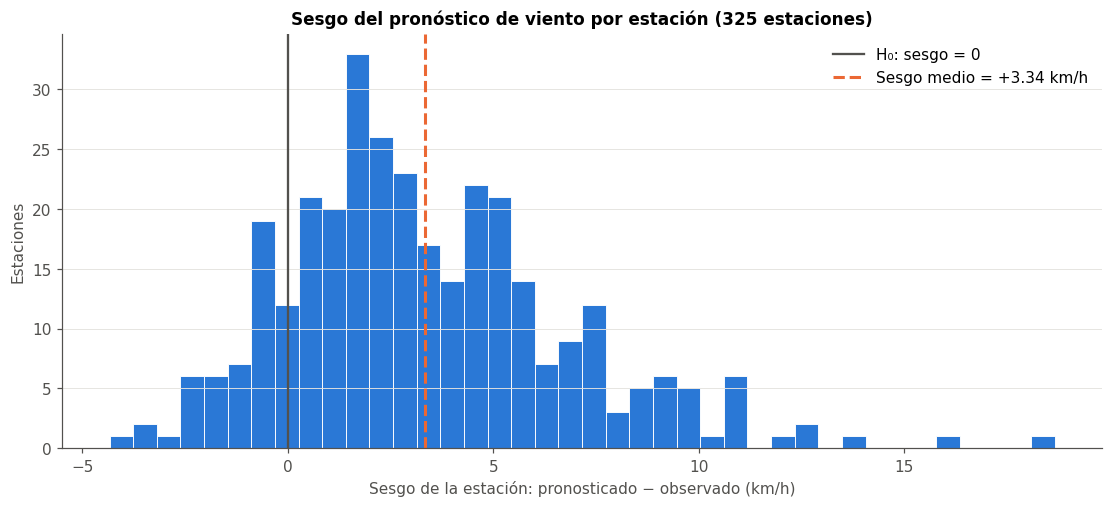

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.hist(x, bins=40, color=AZUL, edgecolor='white', linewidth=0.6)
ax.axvline(0, color=GRIS_TEXTO, lw=1.5, label='H₀: sesgo = 0')
ax.axvline(x.mean(), color=NARANJA, lw=2, ls='--', label=f'Sesgo medio = {x.mean():+.2f} km/h')
ax.set(title=f'Sesgo del pronóstico de viento por estación ({n_est} estaciones)',
       xlabel='Sesgo de la estación: pronosticado − observado (km/h)', ylabel='Estaciones')
ax.legend(frameon=False)
ax.grid(axis='x', visible=False)
figuras['01_sesgo_por_estacion'] = fig
plt.show()

Cada barra cuenta estaciones. Si no hubiera sesgo, el histograma estaría centrado en la línea gris (0), con tantas
estaciones a la izquierda como a la derecha. Los cuatro contrastes que siguen miden, de formas distintas, cuán lejos está
el histograma de esa situación.

## 6. Test t sobre el sesgo por estación

Es el mismo test t de la sección 4, pero ahora cada dato es una estación. Con varios cientos de estaciones la media se
comporta de forma normal aunque el histograma sea algo asimétrico, así que el supuesto 2 se cumple. El supuesto 1
(independencia) se cumple mucho mejor que antes, aunque no del todo: las estaciones vecinas comparten el clima.

### Qué es un intervalo de confianza

El **intervalo de confianza del 95 % (IC 95 %)** es el rango de valores del sesgo verdadero que son compatibles con los
datos. Se construye como *media ± (≈ 2 errores estándar)*. Se lee así:

- Si el intervalo **no incluye el 0**, «no hay sesgo» no es compatible con los datos: equivale a rechazar H₀ con α = 0,05.
- El **ancho** del intervalo indica la precisión: cuanto más angosto, mejor se conoce el sesgo.

Aporta más que el p-valor solo, porque además de decir *si* hay sesgo dice *de qué tamaño* es.

In [9]:
t_est = stats.ttest_1samp(x, 0)
ic_t = stats.t.interval(1 - ALFA, n_est - 1, loc=x.mean(), scale=stats.sem(x))
resultados['Test t (por estación)'] = {
    'Unidad': 'Estación', 'n': n_est, 'Estimación': f'media = {x.mean():+.2f} km/h',
    'Estadístico': f't = {t_est.statistic:.1f}', 'p-valor': t_est.pvalue}

print(f'Sesgo medio = {x.mean():+.2f} km/h   IC 95 % = [{ic_t[0]:+.2f}, {ic_t[1]:+.2f}] km/h')
print(f't = {t_est.statistic:.1f} con {n_est - 1} grados de libertad   p-valor = {formato_p(t_est.pvalue)}')
print(decision(t_est.pvalue))

Sesgo medio = +3.34 km/h   IC 95 % = [+2.97, +3.72] km/h
t = 17.6 con 324 grados de libertad   p-valor = 4.5e-49
Se rechaza H₀


## 7. Test de Wilcoxon de rangos con signo

### Qué es el test de Wilcoxon

Es la alternativa al test t que **no usa los valores sino su orden**, y por eso no necesita suponer normalidad ni se deja
arrastrar por unas pocas estaciones con un sesgo enorme. Funciona así:

1. Se ordenan las estaciones según el **tamaño** de su sesgo, sin mirar el signo, y se les da un puesto (*rango*):
   1 a la de sesgo más chico, 2 a la siguiente, y así hasta la de sesgo más grande.
2. Se suman los rangos de las estaciones con sesgo **positivo** (W⁺) y, por separado, los de las de sesgo **negativo** (W⁻).

Si H₀ fuera cierta (sesgos repartidos simétricamente alrededor de 0), las dos sumas serían parecidas. Si una es mucho
mayor que la otra, hay un desplazamiento sistemático hacia ese lado.

La ventaja frente al test t: una estación con un sesgo de +30 km/h pesa por su **puesto** (es «la más grande») y no por
su valor, así que no puede definir el resultado ella sola.

In [10]:
rangos = stats.rankdata(x.abs())
w_pos, w_neg = rangos[x > 0].sum(), rangos[x < 0].sum()
wilcoxon = stats.wilcoxon(x)
resultados['Wilcoxon (por estación)'] = {
    'Unidad': 'Estación', 'n': n_est, 'Estimación': f'mediana = {x.median():+.2f} km/h',
    'Estadístico': f'W⁺ = {w_pos:,.0f}; W⁻ = {w_neg:,.0f}', 'p-valor': wilcoxon.pvalue}

print(f'Suma de rangos positivos W⁺ = {w_pos:,.0f}   negativos W⁻ = {w_neg:,.0f}   '
      f'(si H₀ fuera cierta, ≈ {rangos.sum() / 2:,.0f} cada una)')
print(f'Sesgo mediano = {x.median():+.2f} km/h   p-valor = {formato_p(wilcoxon.pvalue)}')
print(decision(wilcoxon.pvalue))

Suma de rangos positivos W⁺ = 49,696   negativos W⁻ = 3,279   (si H₀ fuera cierta, ≈ 26,488 cada una)
Sesgo mediano = +2.80 km/h   p-valor = 1.2e-42
Se rechaza H₀


## 8. Test de signos

### Qué es el test de signos

Es el contraste más simple de todos y el que responde más literalmente a la palabra *«sistemático»*. Ignora por completo
el tamaño del sesgo y mira solo su **signo**: ¿cuántas estaciones sobreestiman y cuántas subestiman?

Si el pronóstico no tuviera sesgo, que una estación sobreestime o subestime sería como **tirar una moneda**: se esperaría
cerca de la mitad de cada lado. El test (un *test binomial*) calcula la probabilidad de obtener un reparto tan desparejo
como el observado tirando una moneda equilibrada una vez por estación.

Es como preguntarse si una moneda está cargada después de tirarla cientos de veces: 52 % de caras no llama la atención,
85 % sí.

In [11]:
k = int((x > 0).sum())
signos = stats.binomtest(k, n_est, 0.5)
ic_signos = signos.proportion_ci(1 - ALFA)
resultados['Test de signos (por estación)'] = {
    'Unidad': 'Estación', 'n': n_est, 'Estimación': f'{k / n_est:.1%} sobreestiman',
    'Estadístico': f'{k} de {n_est}', 'p-valor': signos.pvalue}

print(f'{k} de {n_est} estaciones sobreestiman el viento ({k / n_est:.1%}); por azar se esperarían ≈ {n_est / 2:.0f}')
print(f'IC 95 % de la proporción = [{ic_signos.low:.1%}, {ic_signos.high:.1%}]   p-valor = {formato_p(signos.pvalue)}')
print(decision(signos.pvalue))

275 de 325 estaciones sobreestiman el viento (84.6%); por azar se esperarían ≈ 162
IC 95 % de la proporción = [80.2%, 88.4%]   p-valor = 8.6e-39
Se rechaza H₀


## 9. Intervalo de confianza por bootstrap

### Qué es el bootstrap

El intervalo de confianza de la sección 6 sale de una fórmula que supone normalidad. El **bootstrap** llega a un
intervalo sin ninguna fórmula ni supuesto, simulando qué pasaría si se repitiera el estudio muchas veces:

1. Se ponen todas las estaciones en una bolsa.
2. Se saca una al azar, se anota su sesgo y **se la devuelve a la bolsa**. Se repite hasta tener tantas como estaciones
   hay (algunas salen repetidas y otras no salen).
3. Se calcula el sesgo medio de esa «muestra nueva».
4. Se repite todo 10.000 veces.

Las 10.000 medias muestran cuánto puede variar el sesgo medio por el solo hecho de qué estaciones tocó observar. El
**IC 95 %** es el rango que deja afuera el 2,5 % más bajo y el 2,5 % más alto de esas medias. Si el 0 queda fuera, el
sesgo no se explica por el azar de la muestra.

Se remuestrean **estaciones enteras** y no pares sueltos, justamente para respetar la dependencia entre las horas de una
misma estación.

In [12]:
rng = np.random.default_rng(SEMILLA)
medias_boot = rng.choice(x.to_numpy(), size=(N_BOOT, n_est), replace=True).mean(axis=1)
ic_boot = np.percentile(medias_boot, [100 * ALFA / 2, 100 * (1 - ALFA / 2)])
# p-valor bootstrap: proporción de remuestras con la media del otro lado del 0 (bilateral)
p_boot = min(1.0, 2 * min((medias_boot <= 0).mean(), (medias_boot >= 0).mean()))
p_boot = max(p_boot, 1 / N_BOOT)  # con N_BOOT remuestras no se puede afirmar un p menor que 1/N_BOOT
resultados['Bootstrap (por estación)'] = {
    'Unidad': 'Estación', 'n': n_est, 'Estimación': f'IC 95 % = [{ic_boot[0]:+.2f}, {ic_boot[1]:+.2f}] km/h',
    'Estadístico': f'{N_BOOT:,} remuestras', 'p-valor': p_boot}

print(f'IC 95 % bootstrap del sesgo medio = [{ic_boot[0]:+.2f}, {ic_boot[1]:+.2f}] km/h   '
      f'(con la fórmula del test t: [{ic_t[0]:+.2f}, {ic_t[1]:+.2f}])')
print(f'Remuestras con sesgo medio ≤ 0: {(medias_boot <= 0).sum()} de {N_BOOT:,}')

IC 95 % bootstrap del sesgo medio = [+2.98, +3.72] km/h   (con la fórmula del test t: [+2.97, +3.72])
Remuestras con sesgo medio ≤ 0: 0 de 10,000


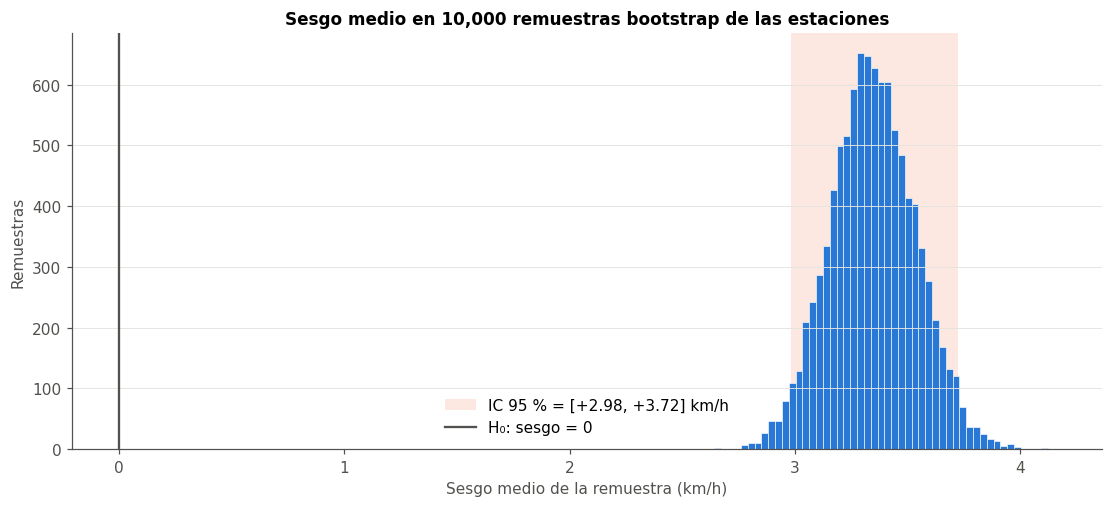

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.hist(medias_boot, bins=50, color=AZUL, edgecolor='white', linewidth=0.4)
ax.axvspan(*ic_boot, color=NARANJA, alpha=0.15, linewidth=0, zorder=0,
           label=f'IC 95 % = [{ic_boot[0]:+.2f}, {ic_boot[1]:+.2f}] km/h')
ax.axvline(0, color=GRIS_TEXTO, lw=1.5, label='H₀: sesgo = 0')
ax.set(title=f'Sesgo medio en {N_BOOT:,} remuestras bootstrap de las estaciones',
       xlabel='Sesgo medio de la remuestra (km/h)', ylabel='Remuestras')
ax.legend(frameon=False)
ax.grid(axis='x', visible=False)
figuras['02_bootstrap_sesgo'] = fig
plt.show()

El histograma muestra todos los valores del sesgo medio que podrían haber salido con otra selección de estaciones. La
distancia entre ese histograma y la línea del 0 es la evidencia contra H₀.

## 10. Tamaño del efecto

### Qué es la d de Cohen

Con muchos datos, casi cualquier diferencia resulta «estadísticamente significativa», aunque sea minúscula. Por eso,
además de preguntar *si* hay sesgo, hay que preguntar **cuán grande es**. La **d de Cohen** expresa el sesgo en unidades
de desvío estándar:

$$d = \frac{\text{media}}{\text{desvío estándar}}$$

Como no tiene unidades, permite juzgar la magnitud con una referencia habitual: ≈ 0,2 es un efecto chico, ≈ 0,5 mediano
y ≈ 0,8 o más, grande.

Se calcula de dos formas, que responden preguntas distintas:

- **Entre estaciones**: el sesgo medio frente a cuánto varía el sesgo de una estación a otra. Dice cuán consistente es la
  sobreestimación entre estaciones.
- **Entre pares**: el sesgo frente a la dispersión del error de un pronóstico individual. Dice cuánto pesa el sesgo en el
  error de cada pronóstico horario.

In [14]:
d_estaciones = x.mean() / x.std()
d_pares = e.mean() / e.std()
print(f'd de Cohen entre estaciones = {d_estaciones:.2f}   (sesgo medio {x.mean():+.2f} / desvío {x.std():.2f} km/h)')
print(f'd de Cohen entre pares      = {d_pares:.2f}   (sesgo {e.mean():+.2f} / desvío {e.std():.2f} km/h)')

d de Cohen entre estaciones = 0.98   (sesgo medio +3.34 / desvío 3.43 km/h)
d de Cohen entre pares      = 0.50   (sesgo +2.89 / desvío 5.74 km/h)


## 11. Chequeo de robustez: por red

Las estaciones pertenecen a redes distintas (CENTERPOINT en Houston, ARDOT en Arkansas, la red de aficionados
APRSWXNET, etc.), con sensores e instalaciones diferentes. Se calcula el sesgo medio y su IC 95 % dentro de cada red
con al menos 10 estaciones. No es un test nuevo: es el intervalo de confianza de la sección 6, repetido por grupo.

Sirve para ver si el sesgo es **general** o si lo produce una sola red: si el intervalo de una red incluye el 0, en esa
red no hay evidencia de sesgo.

In [15]:
def resumen_red(d):
    ic = stats.t.interval(1 - ALFA, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
    return pd.Series({'Estaciones': len(d), 'Sesgo medio': d.mean(), 'IC 95 % inf.': ic[0], 'IC 95 % sup.': ic[1],
                      '% que sobreestiman': (d > 0).mean() * 100})


por_red = pd.DataFrame({red: resumen_red(d) for red, d in por_estacion.groupby('red')['Sesgo'] if len(d) >= N_MIN_RED}).T
por_red = por_red.sort_values('Sesgo medio').astype({'Estaciones': int})
por_red['El IC incluye el 0'] = np.where((por_red['IC 95 % inf.'] <= 0) & (por_red['IC 95 % sup.'] >= 0), 'Sí', 'No')
por_red.round(2)

,Estaciones,Sesgo medio,IC 95 % inf.,IC 95 % sup.,% que sobreestiman,El IC incluye el 0
ARDOT,29,0.08,-0.79,0.96,48.28,Sí
RAWS,12,2.55,0.65,4.45,75.00,No
CENTERPOINT,148,2.70,2.29,3.12,88.51,No
WEATHERSTEM,58,3.14,2.40,3.87,82.76,No
APRSWXNET,62,7.19,6.33,8.05,100.00,No


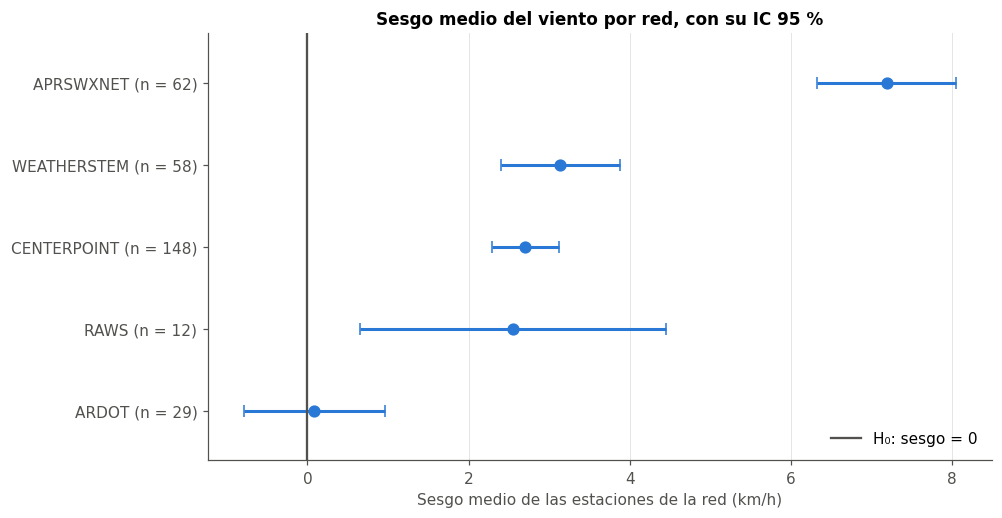

In [16]:
fig, ax = plt.subplots(figsize=(9, 0.6 * len(por_red) + 1.6), constrained_layout=True)
posiciones = np.arange(len(por_red))
ax.errorbar(por_red['Sesgo medio'], posiciones,
            xerr=[por_red['Sesgo medio'] - por_red['IC 95 % inf.'], por_red['IC 95 % sup.'] - por_red['Sesgo medio']],
            fmt='o', color=AZUL, ecolor=AZUL, elinewidth=2, capsize=4, markersize=7)
ax.axvline(0, color=GRIS_TEXTO, lw=1.5, label='H₀: sesgo = 0')
ax.set_yticks(posiciones, [f'{red} (n = {fila["Estaciones"]})' for red, fila in por_red.iterrows()])
ax.set_ylim(-0.6, len(por_red) - 0.4)
ax.set(title='Sesgo medio del viento por red, con su IC 95 %', xlabel='Sesgo medio de las estaciones de la red (km/h)')
ax.legend(frameon=False, loc='lower right')
ax.grid(axis='y', visible=False)
figuras['03_sesgo_por_red'] = fig
plt.show()

Cada punto es el sesgo medio de una red y la barra horizontal, su IC 95 %. Las redes cuyo intervalo queda completo a
la derecha de la línea del 0 sobreestiman el viento de forma significativa.

## 12. Resumen de los contrastes

Todos los contrastes ponen a prueba la misma hipótesis (H₀: el pronóstico de viento no tiene sesgo) con supuestos distintos.
No son cuatro hallazgos independientes, sino cuatro formas de verificar uno solo. Los cuatro coinciden: todos
rechazan H₀ con α = 0,05, así que la conclusión no depende del método elegido.

In [17]:
tabla_resumen = pd.DataFrame(resultados).T.rename_axis('Contraste')
tabla_resumen['Decisión (α = 0,05)'] = tabla_resumen['p-valor'].map(decision)
tabla_resumen['p-valor'] = tabla_resumen['p-valor'].map(formato_p)
tabla_resumen

,Unidad,n,Estimación,Estadístico,p-valor,"Decisión (α = 0,05)"
Contraste,,,,,,
Test t (por estación),Estación,325,media = +3.34 km/h,t = 17.6,4.5e-49,Se rechaza H₀
Wilcoxon (por estación),Estación,325,mediana = +2.80 km/h,"W⁺ = 49,696; W⁻ = 3,279",1.2e-42,Se rechaza H₀
Test de signos (por estación),Estación,325,84.6% sobreestiman,275 de 325,8.6e-39,Se rechaza H₀
Bootstrap (por estación),Estación,325,"IC 95 % = [+2.98, +3.72] km/h","10,000 remuestras",1.0e-04,Se rechaza H₀


In [18]:
rechazan = sum(r['p-valor'] < ALFA for r in resultados.values())
redes_sin_sesgo = por_red.index[por_red['El IC incluye el 0'] == 'Sí'].tolist()

print(f'{rechazan} de {len(resultados)} contrastes rechazan H₀ con α = {ALFA}.')
print(f'Sesgo medio por estación: {x.mean():+.2f} km/h, IC 95 % [{ic_boot[0]:+.2f}, {ic_boot[1]:+.2f}] (bootstrap).')
print(f'Sobreestiman {k} de {n_est} estaciones ({k / n_est:.0%}).')
print(f'Tamaño del efecto: d = {d_estaciones:.2f} entre estaciones y d = {d_pares:.2f} entre pares.')
print('Redes sin evidencia de sesgo (su IC 95 % incluye el 0): ' + (', '.join(redes_sin_sesgo) or 'ninguna') + '.')

4 de 4 contrastes rechazan H₀ con α = 0.05.
Sesgo medio por estación: +3.34 km/h, IC 95 % [+2.98, +3.72] (bootstrap).
Sobreestiman 275 de 325 estaciones (85%).
Tamaño del efecto: d = 0.98 entre estaciones y d = 0.50 entre pares.
Redes sin evidencia de sesgo (su IC 95 % incluye el 0): ARDOT.


### Conclusión

**Se rechaza H₀: el sesgo del pronóstico de viento es sistemático y no se explica por el azar de la muestra.**

- El pronóstico sobreestima el viento en **275 de 325 estaciones (85 %)**, con un sesgo mediano de **+2,80 km/h**. Si el
  sesgo fuera casual, se esperaría cerca de la mitad de cada lado.
- El intervalo de confianza del 95 % del sesgo medio no incluye el 0, ni con la fórmula del test t ni con el bootstrap.
- El resultado se mantiene con los contrastes que no suponen normalidad (Wilcoxon, signos y bootstrap), así que no lo
  explican unas pocas estaciones extremas.

Que el sesgo sea sistemático no indica todavía su origen: puede venir del modelo o de cómo y dónde miden las estaciones.
Esa es la pregunta de las hipótesis siguientes.

## 13. Exportación de los gráficos y las tablas

In [19]:
os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_resumen.to_csv(OUT + 'tabla_resumen_contrastes.csv')
por_estacion.to_csv(OUT + 'tabla_sesgo_viento_por_estacion.csv')
por_red.to_csv(OUT + 'tabla_sesgo_viento_por_red.csv')
print(f'Guardados {len(figuras)} gráficos y 3 tablas en {OUT}')

Guardados 3 gráficos y 3 tablas en ../data/processed/hipotesis/
